# Week 4 — Logistic Regression and Classification Evaluation


### A1. 
Regression predicts a number, while classification predicts a category. Predicting next month’s sales amount is regression because the answer is a number. Predicting if a customer will leave next month is classification because the answer is yes or no. Deciding whether to approve a loan is also classification because there are two classes.

### A2. 
First, linear regression can give values below 0 or above 1, which cannot be probabilities. Logistic regression uses the sigmoid function to keep predictions between 0 and 1. Second, a straight line is not a good model for a binary probability, and using squared error can make learning less suitable. Logistic regression models log-odds and normally uses log loss for binary outcomes.

### A3. 
The sigmoid function is $\sigma(z)=1/(1+e^{-z})$. At zero, it equals 0.5; when $z$ goes to negative infinity it approaches 0; when $z$ goes to positive infinity it approaches 1. This is useful for probability because the result stays between 0 and 1. The equation $\sigma(-z)=1-\sigma(z)$ means opposite scores give complementary probabilities.

### A4. 
MSE measures squared differences between the target and the prediction. Log loss is better suited to binary probability models and strongly penalizes confident wrong predictions. For example, if the true label is 1 but the model predicts 0.01, the log loss is about 4.605. Log loss also gives logistic regression a convenient convex objective for its linear parameters.

### A5. 
Precision is $TP/(TP+FP)$: of predicted positives, how many are correct? Recall is $TP/(TP+FN)$: of real positives, how many did we find? For a spam filter, precision may matter more because a real email should not be hidden as spam. For loan default prediction, recall is important when missing a default is costly; for an infectious disease screening test, recall is important because missing an infected person can cause harm. The final choice always depends on the costs of both errors.

## Part B — Logistic regression from scratch

### Dataset from Appendix A (unchanged)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

X, y = make_classification(
    n_samples=4000, n_features=8, n_informative=5,
    n_redundant=1, weights=[0.94, 0.06],
    flip_y=0.03, class_sep=1.1, random_state=4)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print('Shapes:', X.shape, X_train.shape, X_test.shape)
print('Test defaults:', y_test.sum(), 'out of', len(y_test))

Shapes: (4000, 8) (3000, 8) (1000, 8)
Test defaults: 73 out of 1000


### B1. Stable sigmoid 

In [2]:
def sigmoid(z):
    z = np.clip(np.asarray(z, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-z))

values = np.array([-1000, -2, 0, 2, 1000])
print('Sigmoid values:', np.round(sigmoid(values), 4))

Sigmoid values: [0.     0.1192 0.5    0.8808 1.    ]


For a very negative number, `-z` is very large and `exp(-z)` can overflow. Clipping prevents that warning. Mathematically sigmoid approaches 0 but does not equal 0 for a finite input; in computer arithmetic very small values can round to zero.

### B2. Manual log loss

In [3]:
def log_loss_manual(y, p):
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 1e-12, 1 - 1e-12)
    return float(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))

for yy, pp in [(1, 0.9), (1, 0.1), (0, 0.9)]:
    print(f'y={yy}, p={pp}: loss={log_loss_manual(yy, pp):.4f}')

y=1, p=0.9: loss=0.1054
y=1, p=0.1: loss=2.3026
y=0, p=0.9: loss=2.3026


The value 2.3026 is $-\ln(0.1)=\ln(10)$. A confident wrong prediction gets a high loss. Clipping prevents `log(0)`.

### B3. Gradient descent 

First loss: 0.6931
Last recorded loss: 0.1625
Manual test AUC: 0.8766


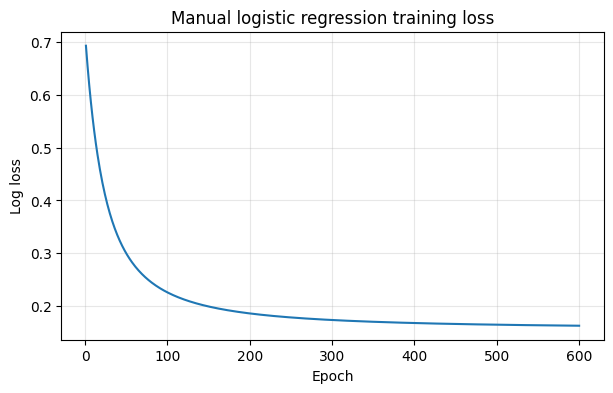

In [4]:
scaler = StandardScaler()
Xs_train = scaler.fit_transform(X_train)
Xs_test = scaler.transform(X_test)  # Do not fit on test data
Xb_train = np.c_[np.ones(len(Xs_train)), Xs_train]
Xb_test = np.c_[np.ones(len(Xs_test)), Xs_test]
w = np.zeros(Xb_train.shape[1])
learning_rate = 0.1
losses = []
for epoch in range(600):
    p_train = sigmoid(Xb_train @ w)
    losses.append(log_loss_manual(y_train, p_train))
    grad = Xb_train.T @ (p_train - y_train) / len(y_train)
    w -= learning_rate * grad

p_manual = sigmoid(Xb_test @ w)
manual_auc = roc_auc_score(y_test, p_manual)
print('First loss:', round(losses[0], 4))
print('Last recorded loss:', round(losses[-1], 4))
print('Manual test AUC:', round(manual_auc, 4))
plt.figure(figsize=(7, 4))
plt.plot(range(1, 601), losses)
plt.xlabel('Epoch')
plt.ylabel('Log loss')
plt.title('Manual logistic regression training loss')
plt.grid(alpha=.3)
plt.show()

At the beginning all weights are zero, so each prediction is 0.5. The loss for each example is $-\ln(0.5)=\ln(2)\approx0.6931$. Training changes the weights to reduce the loss.

## Part C — scikit-learn 

### C1. Pipeline and evaluation 

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (log_loss, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score

model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))
model.fit(X_train, y_train)
p = model.predict_proba(X_test)[:, 1]
sklearn_loss = log_loss(y_test, p)
sklearn_auc = roc_auc_score(y_test, p)
print('Test log loss:', round(sklearn_loss, 4))
print('Test ROC-AUC:', round(sklearn_auc, 4))
print('Manual ROC-AUC:', round(manual_auc, 4))

Test log loss: 0.1489
Test ROC-AUC: 0.871
Manual ROC-AUC: 0.8766


Both models use logistic regression on the same data, so their AUC values are close. They may differ because scikit-learn uses regularization and a different optimization method. `predict_proba` gives class probabilities, while `predict` gives class labels using the default decision rule.

### C2. Four decision thresholds

 Threshold  TN  FP  FN  TP  Accuracy  Precision  Recall    F1
     0.500 924   3  39  34     0.958      0.919   0.466 0.618
     0.350 918   9  29  44     0.962      0.830   0.603 0.698
     0.250 907  20  26  47     0.954      0.701   0.644 0.671
     0.150 872  55  21  52     0.924      0.486   0.712 0.578


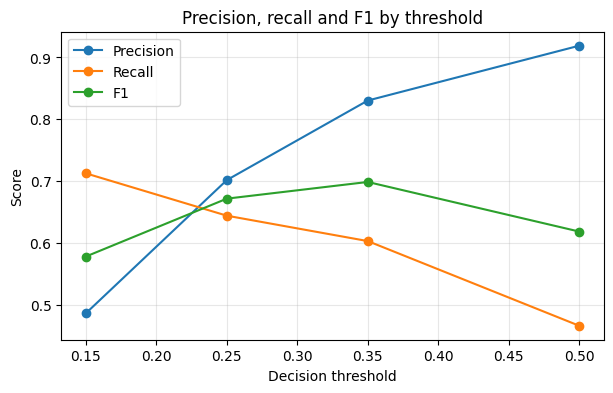

In [6]:
thresholds = [0.50, 0.35, 0.25, 0.15]
rows = []
for t in thresholds:
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({'Threshold': t, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred, zero_division=0),
                 'F1': f1_score(y_test, pred, zero_division=0)})
results = pd.DataFrame(rows)
print(results.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
plt.figure(figsize=(7, 4))
for metric in ['Precision', 'Recall', 'F1']:
    plt.plot(results['Threshold'], results[metric], marker='o', label=metric)
plt.xlabel('Decision threshold')
plt.ylabel('Score')
plt.title('Precision, recall and F1 by threshold')
plt.legend()
plt.grid(alpha=.3)
plt.show()

Lowering the threshold predicts more defaults. This usually increases recall because fewer real defaults are missed. Precision may decrease because more good borrowers are incorrectly flagged.

### C3. Five-fold cross-validation

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
print('Fold AUC:', np.round(cv_scores, 3))
print(f'Mean ± SD: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}')
print(f'Single test AUC: {sklearn_auc:.3f}')

Fold AUC: [0.876 0.866 0.849 0.902 0.856]
Mean ± SD: 0.870 ± 0.019
Single test AUC: 0.871


Cross-validation uses several training/validation splits, so it gives a more stable view than one split. The held-out test set is still useful for checking final performance on unseen data.

### C4. Cost analysis 

 Threshold  FN  FP  Cost
      0.05  13 202   332
      0.10  18  97   277
      0.15  21  55   265
      0.20  24  31   271
      0.25  26  20   280
      0.30  26  14   274
      0.35  29   9   299
      0.40  32   6   326
      0.45  36   3   363
      0.50  39   3   393
      0.55  41   3   413
      0.60  44   3   443
      0.65  45   1   451
      0.70  47   0   470
      0.75  48   0   480
      0.80  53   0   530
      0.85  60   0   600
      0.90  63   0   630
      0.95  67   0   670
Lowest cost: 265 at threshold 0.15
Cost at 0.50: 393


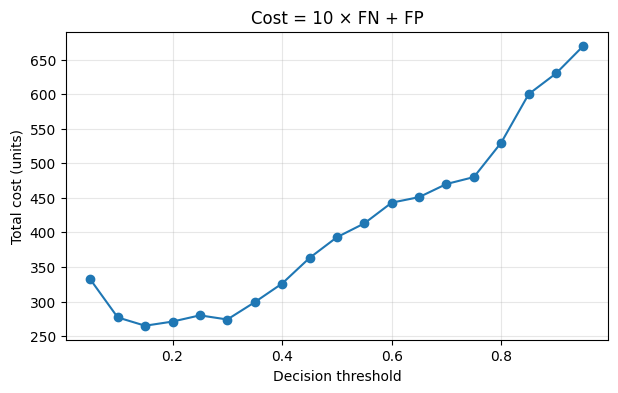

In [8]:
cost_rows = []
for t in np.round(np.arange(0.05, 0.951, 0.05), 2):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    cost_rows.append({'Threshold': t, 'FN': fn, 'FP': fp, 'Cost': 10 * fn + fp})
cost_table = pd.DataFrame(cost_rows)
print(cost_table.to_string(index=False))
best = cost_table.loc[cost_table['Cost'].idxmin()]
base = cost_table.loc[np.isclose(cost_table['Threshold'], 0.5)].iloc[0]
print(f"Lowest cost: {best['Cost']:.0f} at threshold {best['Threshold']:.2f}")
print(f"Cost at 0.50: {base['Cost']:.0f}")
plt.figure(figsize=(7, 4))
plt.plot(cost_table['Threshold'], cost_table['Cost'], marker='o')
plt.xlabel('Decision threshold')
plt.ylabel('Total cost (units)')
plt.title('Cost = 10 × FN + FP')
plt.grid(alpha=.3)
plt.show()

A threshold of 0.50 is not automatically the best business decision. Missing a default costs ten times more than a false alarm here. The cost table helps select the threshold with the smallest total cost.

